In [1]:
#Dashboard needs
    #-->Volatility curve:
        #--> ATM price marker
        #--> realized volatility
        #--> implied volatility:
            #--> plot distribution
            #--> standard dev
    #Necessary Data:
        #--> Greeks
            #--> delta distribution from BS
            #--> Gamma Data 
            #--> Theta Data
        #--> Risk Profiles

    #Volume
    #Orderbook

    #Historical Indicators:
        #--> MACD
        #--> RSI
        #--> Bollinger Bands

#Need to figure out:
#--> Risk Management:
    #--> Order Sizing

In [2]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import scipy.optimize as opt
from scipy.interpolate import griddata
import matplotlib.pyplot as plt

import nest_asyncio

from datetime import datetime, timedelta

import os
from dotenv import load_dotenv, dotenv_values 
from pathlib import Path

from alpaca.trading.client import TradingClient
from alpaca.data.historical.stock import (
    StockLatestTradeRequest,
    StockHistoricalDataClient, 
    StockBarsRequest
)
from alpaca.data.historical.option import OptionHistoricalDataClient

from alpaca.data.timeframe import TimeFrame, TimeFrameUnit

#Live data
#from alpaca.trading.stream import TradingStream
#from alpaca.data.live.option import OptionDataStream


from alpaca.data.requests import (
    #OptionBarsRequest,
    #OptionTradesRequest,
    OptionLatestQuoteRequest,
    OptionLatestTradeRequest,
    OptionSnapshotRequest,
    OptionChainRequest
)
from alpaca.trading.requests import (
    GetOptionContractsRequest,
    GetAssetsRequest,
    MarketOrderRequest,
    GetOrdersRequest,
    ClosePositionRequest
    #OptionLegRequest
)

from alpaca.trading.enums import (
     AssetStatus,
#    ExerciseStyle,
#    OrderSide,
#    OrderClass,
#    OrderType,
#    TimeInForce,
#    QueryOrderStatus,
    ContractType
)

from alpaca.common.exceptions import APIError
nest_asyncio.apply()


In [3]:
def get_underlying_price(symbol):
    # Get the latest trade for the underlying stock
    underlying_trade_request = StockLatestTradeRequest(symbol_or_symbols=symbol)
    underlying_trade_response = stock_data_client.get_stock_latest_trade(underlying_trade_request)
    return underlying_trade_response[symbol].price


In [4]:
def get_options(underlying_symbol, expiration_start, expiration_end, option_type, strike_range=0.10):
    
    underlying_price=get_underlying_price(underlying_symbol)
    
    min_strike = str(5*np.ceil(
        (underlying_price * (1 - strike_range))/5)
    )
    max_strike = str(5*np.floor(
        (underlying_price * (1 + strike_range))/5)
    )

    option_contracts_request=GetOptionContractsRequest(
        underlying_symbols=[underlying_symbol],
        status=AssetStatus.ACTIVE,
        strike_price_gte=min_strike,
        strike_price_lte=max_strike,
        expiration_date_gte = expiration_start,                            
        expiration_date_lte = expiration_end, 
        # specify option type (ContractType.CALL or ContractType.PUT)
        type = option_type
    )
    
    option_contracts=trading_client.get_option_contracts(option_contracts_request).option_contracts
    snapshot_request = OptionSnapshotRequest(
        symbol_or_symbols = [s.symbol for s in option_contracts]  
    )
    snapshot=option_data_client.get_option_snapshot(snapshot_request)
    
    option_list=[]

    for s in option_contracts:
        if s.symbol in snapshot:
            j=snapshot[s.symbol]
            option_dict={
                'symbol':j.symbol,
                'implied_volatility':j.implied_volatility,
                'delta':j.greeks.delta if j.greeks is not None else None,
                'gamma':j.greeks.gamma if j.greeks is not None else None,
                'rho':j.greeks.rho if j.greeks is not None else None,
                'theta':j.greeks.theta if j.greeks is not None else None,
                'vega':j.greeks.vega if j.greeks is not None else None,
                'ask':j.latest_quote.ask_price,
                'ask_size':j.latest_quote.ask_size,
                'bid':j.latest_quote.bid_price,
                'bid_size':j.latest_quote.bid_size,
                'mid':(j.latest_quote.ask_price+j.latest_quote.bid_price)/2,
                'id':s.id,
                'underlying_symbol':s.underlying_symbol,
                'expiration':s.expiration_date,
                'strike':s.strike_price,
                'type':s.type,
                'size':s.size
            }
            option_list.append(option_dict)
    
    return pd.DataFrame(option_list)


In [5]:
def time_til_exp(date):
    if type(date) is datetime: 
        pass
    elif type(date) is str:
        date=datetime.strptime(date, DATE_STRING_FORMAT)
    
    delta=date-TODAY.date()
    
    return (delta / pd.Timedelta(days=1))

def black_scholes(S, K, T, sigma, contract_type, r=0.01):

    d_t=T/252

    d1 = (np.log(S/K) + (r + (sigma**2)/2)*d_t) / (sigma*np.sqrt(d_t))
    d2 = d1 - sigma*np.sqrt(d_t)

    if contract_type is ContractType.CALL or contract_type == 'CALL':
        sol = (
            S*stats.norm.cdf(d1)
            - K*np.exp(-r*d_t)*stats.norm.cdf(d2)
        )
    elif contract_type is ContractType.PUT or contract_type == 'PUT':
        sol = (
            K*np.exp(-r*d_t)*stats.norm.cdf(-d2)
            -S*stats.norm.cdf(-d1)
        )

    return sol


def C_Greeks(S, K, d_t, sigma, r=0.01):
    d1 = (np.log(S/K) + (r + sigma**2/2)*d_t) / (sigma*np.sqrt(d_t))
    d2 = d1 - sigma*np.sqrt(d_t)
    DRV=stats.norm.pdf(d1)

    Delta=stats.norm.cdf(d1)
    
    Theta=(-r*K*np.exp(-r*d_t)*stats.norm.cdf(d2)
            -(sigma*S/(2*d_t))*DRV)
    
    Gamma=DRV/(sigma*S*np.sqrt(d_t))
    
    Vega=S*np.sqrt(d_t)*DRV
    
    Rho=K*d_t*np.exp(-r*d_t)*stats.norm.cdf(d2)

    return {
        'Delta': Delta,
        'Theta': Theta,
        'Gamma': Gamma,
        'Vega': Vega,
        'Rho': Rho
    }

In [6]:
def brent_vol(option_price, S, K, T, contract_type):
    a=0.002
    b=6.0

    if pd.isna(option_price) or option_price <= 0:
        return np.nan

    if pd.isna(S) or pd.isna(K) or pd.isna(T):
        return np.nan

    def price(x):
        bs_price = black_scholes(
            S=S,
            K=K, 
            T=T,
            r=0.02,
            sigma=x, 
            contract_type=contract_type
        )
        
        return bs_price - option_price
        
    try:
        return opt.brentq(price, 1e-6, 5.0)
    except ValueError:
        return np.nan
        
    return opt.brentq(price, a, b)

In [7]:
#dataprep
def plot_df(df):
    plot_df = df[['days_until_exp', 'strike', 'imp_vol', 'implied_volatility']].dropna()

    up=get_underlying_price(us)
    interpolation_size=45
    
    X=plot_df['days_until_exp']
    Y=plot_df['strike']
    Z=plot_df['implied_volatility']
    sm_0=plot_df.loc[plot_df['days_until_exp']==np.min(plot_df['days_until_exp'])]
    Y_0=sm_0['strike']
    Z_0=sm_0['implied_volatility']

    xi = np.linspace(X.min(), X.max(), interpolation_size)
    yi = np.linspace(Y.min(), Y.max(), interpolation_size)
    
    Xmesh, Ymesh = np.meshgrid(xi, yi)
    
    Zgrid = griddata(
        (X, Y),
        Z,
        (Xmesh, Ymesh),
        method='linear'
    )
    
    fig = plt.figure(figsize=(16, 9))
    ax1 = plt.subplot2grid((1, 3), (0, 0), colspan=2, projection='3d')
    ax2 = plt.subplot2grid((1, 3), (0, 2))
    
    ax1.plot_surface(
        Xmesh, 
        Ymesh, 
        Zgrid, 
        cmap="plasma"
    )
    
    ax2.plot(
        Y_0,
        Z_0
    )

    ax2.axvline(x=up, ymin=0.0, ymax=1.5, color='r', ls='--')
    
    ax1.set_xlabel('Days to Expiration')
    ax1.set_ylabel('Strike')
    ax1.set_zlabel('Implied Volatility')

    ax2.set_xlabel('Strike')
    ax2.set_ylabel('IV')
    
    plt.show()

In [8]:
def plot_df_2(df):

    pivot = df.pivot_table(index='days_until_exp', columns='strike', values='imp_vol').sort_index().sort_index(axis=1)
    
    pivot = pivot.interpolate(method='linear', axis=1).ffill().bfill()
    
    X_i, Y_i = np.meshgrid(pivot.index, pivot.columns)
    #X_i, Y_i = np.meshgrid(xiq, yiq)
    
    QG_fig=plt.figure(figsize=(12, 6))
    
    QG_ax_3d=plt.subplot2grid((1,3),(0,0), colspan=2, projection='3d')
    #QG_ax_2d=QG_fig.add_subplot(111, projection='3d')
    
    QG_ax_3d.clear()
    QG_ax_3d.plot_surface(
        Y_i, 
        X_i, 
        pivot.values.T, 
        cmap="plasma",
        alpha=0.9
    )
    
    QG_ax_3d.set_ylabel('Strike')
    QG_ax_3d.set_xlabel('Days to Expiration')
    QG_ax_3d.set_zlabel('Implied Volatility')
    
    plt.show()

In [9]:
def return_data(u_s, window=2):
    historical_stock_request=StockBarsRequest(
        symbol_or_symbols=[u_s],
        start=TODAY-timedelta(days=750),
        timeframe=TimeFrame(amount=1, unit=TimeFrameUnit(value='Day'))
    )
    
    stock_bars=stock_data_client.get_stock_bars(historical_stock_request).df.reset_index(level='symbol', drop=True)
    
    stock_bars['Returns']=stock_bars['close'].pct_change()
    stock_bars['Cumsum_Returns']=stock_bars['close'].pct_change().cumsum()
    stock_bars['MEAN']=stock_bars['Returns'].mean()
    stock_bars['STD_DEV']=stock_bars['Returns'].std()
    stock_bars[f'{window} Day Rolling MEAN']=stock_bars['Returns'].rolling(window).mean()
    stock_bars[f'{window} Day Rolling STD_DEV']=stock_bars['Returns'].rolling(window).std()

    return stock_bars
    
    #stock_data_df=pd.DataFrame(stock_bars.data[underlying_symbol])

In [10]:
def cherry_pick(file):
    try:
        with open(file) as f:
            cash_app_symbols = [line.strip() for line in f]
    except:
        print('We Got An Exception Over Hea!!!')
    rng=np.random.default_rng()
    num=rng.integers(low=0, high=len(cash_app_symbols))
    
    if len(cash_app_symbols):
        underlying_symbol=cash_app_symbols[num]

        return underlying_symbol
    else:
        print('You No Have Symbols!!')

In [11]:
def get_calls_puts(file=None, underlying_symbol=None):
    #time prep
    if underlying_symbol == None:
        if file != None: 
            underlying_symbol = cherry_pick(file)
        else:
            print('No Data Available')
    
    tte=700
    DATE_STRING_FORMAT="%Y-%m-%d"
    
    today_str=TODAY.strftime(DATE_STRING_FORMAT)
    
    exp_start=(TODAY-timedelta(days=tte)).strftime(DATE_STRING_FORMAT)
    exp_end=(TODAY+timedelta(days=tte)).strftime(DATE_STRING_FORMAT)
    
    #price prep
    strike_range=0.10
    
    #money prep
    #POWER=float(trade_client.get_account().buying_power)
    #LIMIT=(0.10)
    risk_free_rate=0.01
    
    calls=get_options(
        underlying_symbol=underlying_symbol, 
        expiration_start=exp_start, 
        expiration_end=exp_end, 
        option_type=ContractType.CALL, 
        strike_range=strike_range
    )
    puts=get_options(
        underlying_symbol=underlying_symbol, 
        expiration_start=exp_start, 
        expiration_end=exp_end, 
        option_type=ContractType.PUT, 
        strike_range=strike_range
    )
    
    calls['days_until_exp']=time_til_exp(calls['expiration'])
    puts['days_until_exp']=time_til_exp(puts['expiration'])
    
    underlying_price=get_underlying_price(underlying_symbol)
    
    calls['imp_vol']=calls.apply(
        lambda row: brent_vol(
            option_price=row['mid'], 
            S=underlying_price, 
            K=row['strike'], 
            T=row['days_until_exp'],
            contract_type="CALL"
        ),
        axis=1
    )
    puts['imp_vol']=puts.apply(
        lambda row: brent_vol(
            option_price=row['mid'], 
            S=underlying_price, 
            K=row['strike'], 
            T=row['days_until_exp'],
            contract_type="PUT"
        ),
        axis=1
    )
    
    calls['Percent_Error']=(np.abs(calls['imp_vol']-calls['implied_volatility'])/calls['implied_volatility'])*100
    puts['Percent_Error']=(np.abs(puts['imp_vol']-puts['implied_volatility'])/puts['implied_volatility'])*100

    return calls, puts, underlying_symbol


CRWD


C:\Users\USER\AppData\Local\Temp\ipykernel_13644\3598345056.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  return (delta / pd.Timedelta(days=1))
C:\Users\USER\AppData\Local\Temp\ipykernel_13644\3598345056.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  return (delta / pd.Timedelta(days=1))


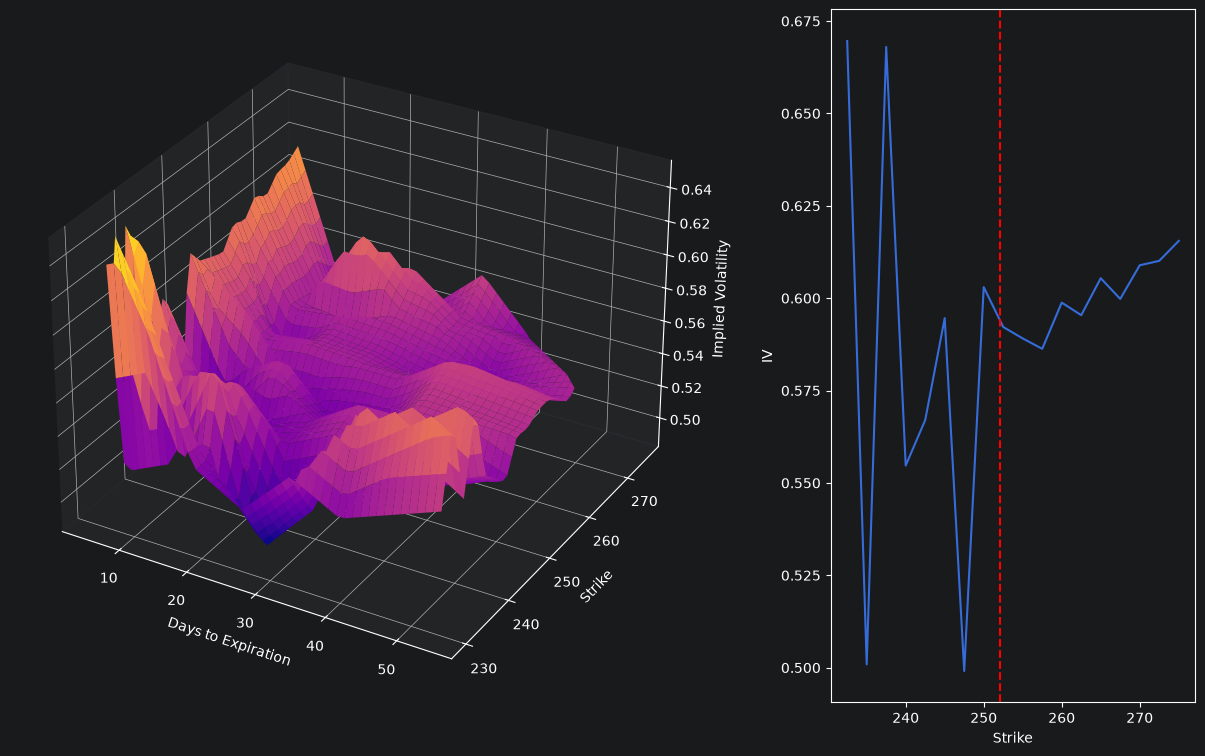

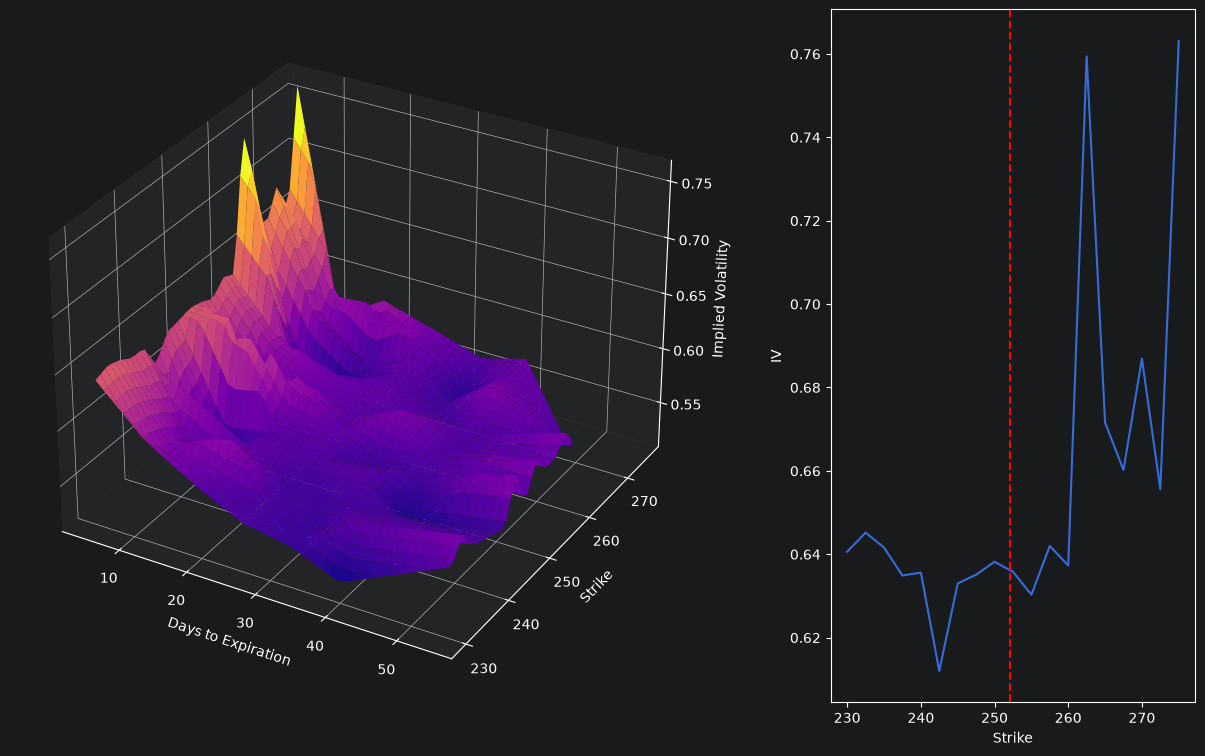

In [14]:
load_dotenv()

source1='cashapp.txt'
source2='s&p500.txt'

API_KEY = os.getenv("APCA_API_KEY_ID")
SECRET_KEY = os.getenv("APCA_API_SECRET_KEY")

BASE_URL=None
TRADE_API_WSS = None
DATA_API_URL = None
OPTION_STREAM_DATA_WSS = None

PAPER_TRADE=True

trading_client = TradingClient(
    api_key=API_KEY,
    secret_key=SECRET_KEY,
    paper=PAPER_TRADE  # False for live trading
)

option_data_client = OptionHistoricalDataClient(
    api_key=API_KEY, 
    secret_key=SECRET_KEY, 
    url_override=BASE_URL
)

stock_data_client = StockHistoricalDataClient(
    api_key=API_KEY, 
    secret_key=SECRET_KEY
)

with open(source2) as f:
    c_a_s = [line.strip() for line in f]


TODAY=datetime.now()

account = trading_client.get_account()

rng=np.random.default_rng()
num=rng.integers(low=0, high=len(c_a_s))
print(c_a_s[num])

df_c, df_p, us=get_calls_puts(underlying_symbol=c_a_s[num])

plot_df(df_c)
plot_df(df_p)


262.5 17.92 ContractType.CALL


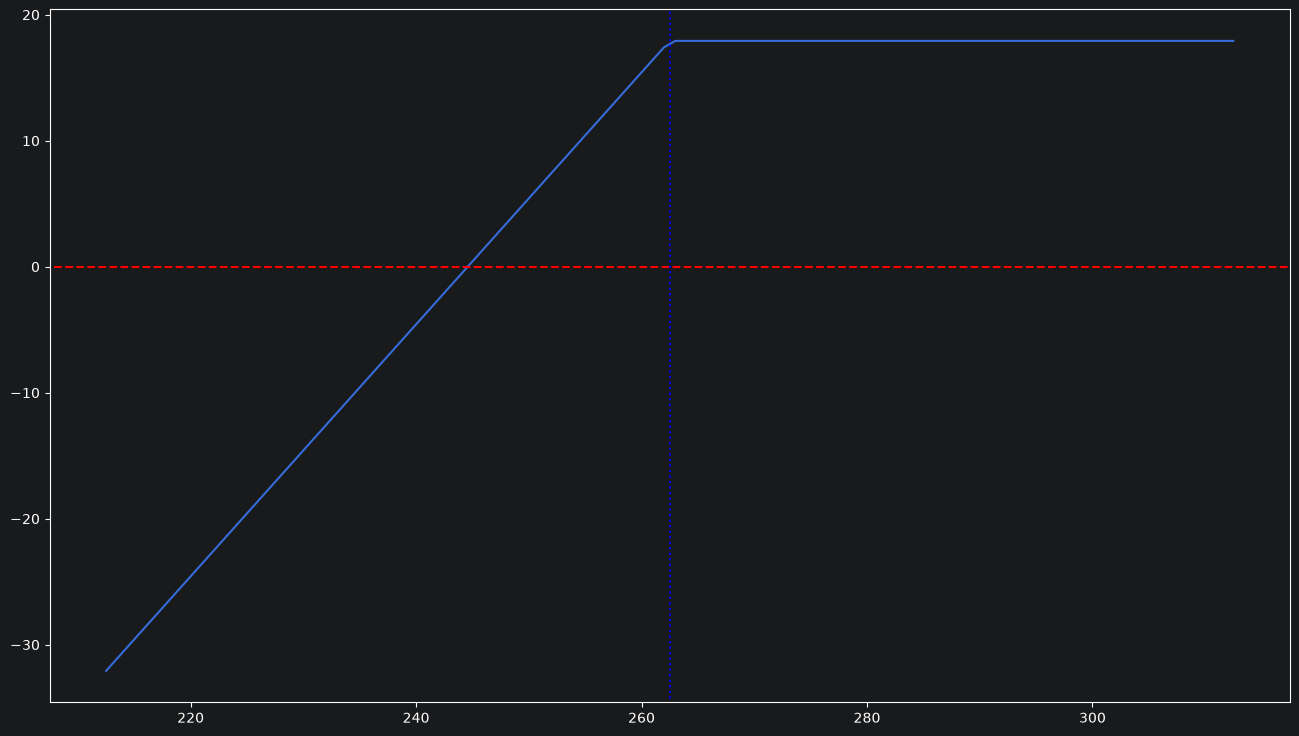

In [15]:
#RSI strat
#MACD strat

#Options Multi-leg Graph
#VA
test=df_c.iloc[-1]

def c_p_payoff(K, premium, otype, long_or_short="long", rng=50):
    strike_range=np.linspace(K-rng,K+rng, rng*2)
    eq=None
    if otype is ContractType.CALL:
        eq=strike_range-K
    if otype is ContractType.PUT:
        eq=K-strike_range

    if long_or_short == "long":
        payoff=np.maximum(eq, 0)-premium
    if long_or_short == "short":
        payoff=np.minimum(eq, 0)+premium
    
    return (strike_range, payoff)

r, p = c_p_payoff(K=test['strike'], premium=test['mid'], otype=test['type'], long_or_short="short")
print(test['strike'],test['mid'],test['type'],)

figure1 = plt.figure(figsize=(16, 9))
ax1 = plt.subplot()

ax1.plot(
    r,
    p
)

ax1.axhline(y=0.0, xmin=np.min(p), xmax=np.max(p), color='r', ls='--')
ax1.axvline(x=test['strike'], ymin=np.min(p), ymax=np.max(p), color='b', ls=':')



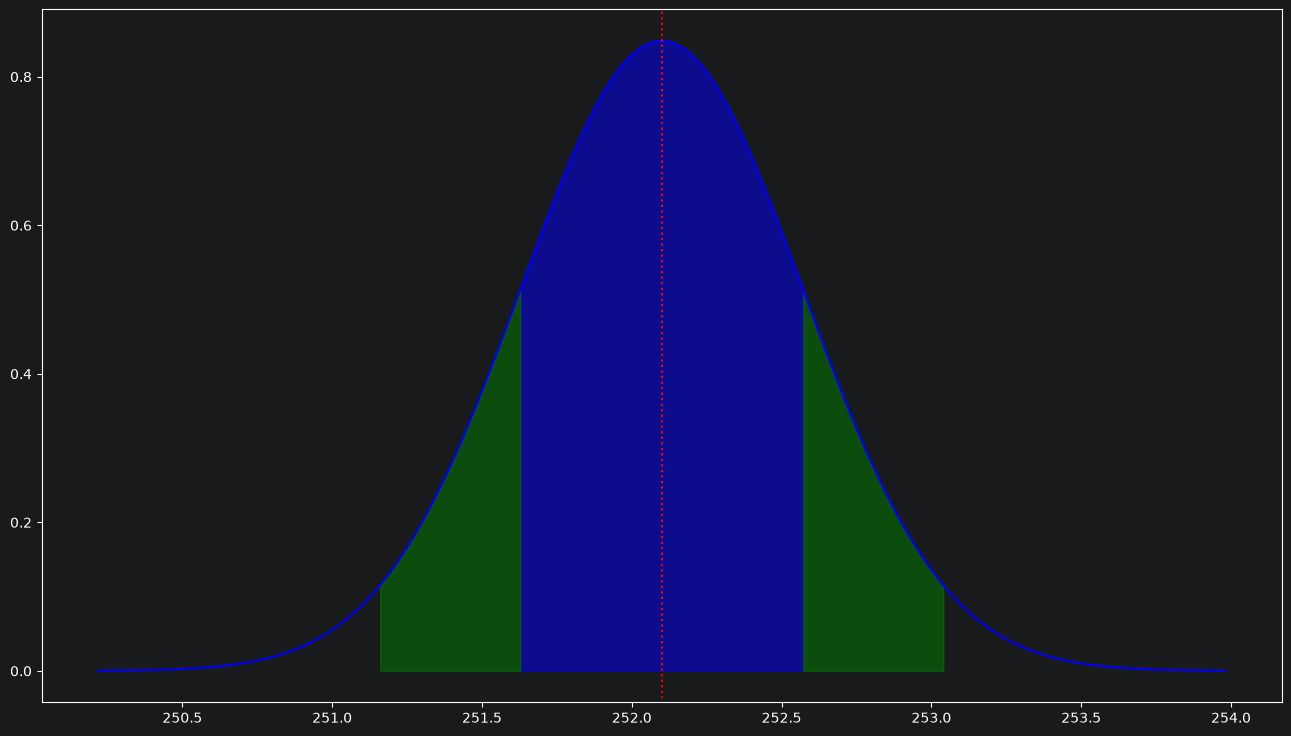

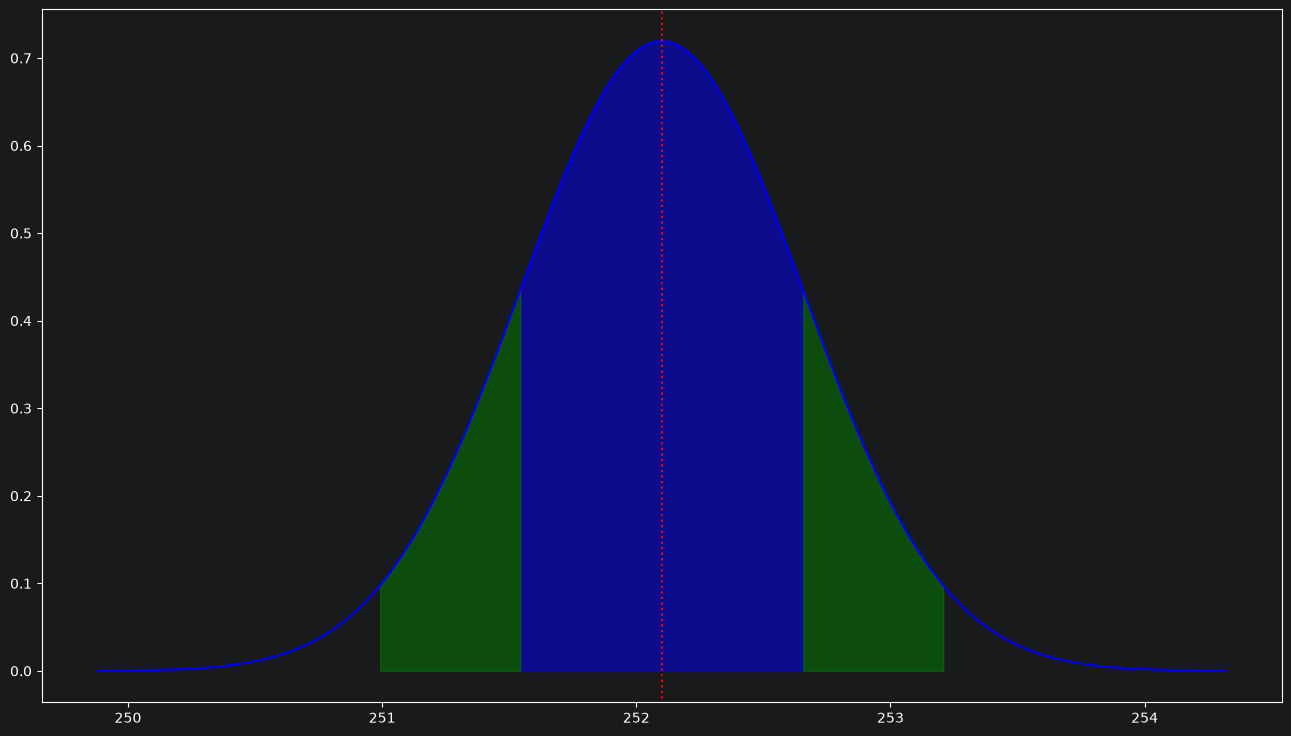

In [16]:

strike=test['strike']

implied_vol=test['imp_vol']
clc_imp_vol=test['implied_volatility']
underlying_symbol=test['underlying_symbol']
underlying_price=get_underlying_price(underlying_symbol)

#rang=50
#prc_range = np.linspace(underlying_price-rang,underlying_price+rang, rang*2)
#prc_range2 = np.linspace(
#    stats.norm.ppf(0.01),
#    stats.norm.ppf(0.99),
#    100
#)
def plot_dist_1(underlying_price, imp_vol):
    prc_range = np.linspace(underlying_price - 4*imp_vol, underlying_price + 4*imp_vol, 1000)
    normal= (1 / (imp_vol * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((prc_range - underlying_price) / imp_vol)**2)


    figure2 = plt.figure(figsize=(16,9))
    ax2=plt.subplot()
    ax2.plot(
        prc_range,
        normal,
        color="blue"
    )

    ax2.axvline(
        x=underlying_price,
        ymin=-1.0,
        ymax=np.max(normal)+1,
        ls=':',
        color='red'
    )
    #1 standard dev
    ax2.fill_between(prc_range,
                     normal,
                     where=(prc_range >= underlying_price-imp_vol) & (prc_range <= underlying_price+imp_vol),
                     color='blue',
                     alpha=0.5
    )

    #2 standard dev
    ax2.fill_between(prc_range,
                     normal,
                     where=(prc_range >= underlying_price-2*imp_vol)
                           &(prc_range <= underlying_price-imp_vol),
                     color='green',
                     alpha=0.5
    )
    ax2.fill_between(prc_range,
                     normal,
                     where=(prc_range >= underlying_price+imp_vol)
                           &(prc_range <= underlying_price+2*imp_vol),
                     color='green',
                     alpha=0.5
    )


    plt.show()

plot_dist_1(underlying_price=underlying_price, imp_vol=implied_vol)
plot_dist_1(underlying_price=underlying_price, imp_vol=clc_imp_vol)